## Supp Fig 1

In [1]:
import os
from domino.data.data import *
from scipy import stats
from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
import matplotlib.pyplot as plt
from domino.utils.tools import seq_from_df
import pandas as pd
import seaborn as sns
import os
from domino.data.data import process_bed_file_df
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'
import fanc
import fanc.plotting as fancplot

import coolbox
from coolbox.api import *

import sys
sys.path.append('../../../python_modules/')
from generic_plotting_functions import *

In [2]:
mcool_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/wenfan_merged/GSE263270_nh_forward_merged.mcool"

mut2mcool = {
    'st14_wt': "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/wenfan_merged/GSE263270_nh_forward_merged.mcool",
    'nc14_wt': "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/new_nc14_embryo_merged_all_11.mcool"
}
mut2ins = {
    'st14_wt': "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/GSE263270_nh_forward_merged.resolution=200bp.insulation_1kb.bed",
    'nc14_wt': "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_1kb.bed"
}

mut2coords = {
    'st14_wt': ('chr2R', 9973201, 9973400),
    'nc14_wt': ("chr2R", 9972801, 9973000)
}

In [3]:
def get_true_track(boundary, ins1_path, ins_score_context_bin_width=10, resolution=200, bp_radius=20_000):
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')
    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]
    
    ins_score_context_bin_width=10
    idxs_pos = np.array([np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1) for i in locus_df.index])
    y_pos = np.array([np.array(ins_score1['ins_score'][idx_arr]) for idx_arr in idxs_pos]) # context with middle bin
    
    demeaned_y1_pos = y_pos - np.mean(y_pos, axis=1)[:, np.newaxis]
    middle_points1_pos = demeaned_y1_pos[:, ins_score_context_bin_width]

    
    x, y = np.arange(len(middle_points1_pos)), middle_points1_pos
    return x, y

def save_track(y, boundary, fn, resolution=200, offset=20_000):
    chrom, start, end = boundary
    df = pd.DataFrame({
        'chrom': [chrom] * len(y),
        'start': np.arange(start - offset, end + offset, resolution),
        'end': np.arange(start - offset, end + offset, resolution) + resolution,
        'value': y
    })
    # Save to BEDGraph
    df.to_csv(fn, sep='\t', header=False, index=False)
    return df

In [4]:
HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=1, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3.5, 
    grid=False,
    color_bar='no'
)

BEDGRAPH_KWARGS = dict(
    border_only=True,
    labels=False,
    num_rows=1,
    linewidth=4,
    height=2,
    style='line',
    line_width=3,
    alpha=0.9,
    border_color=None,
)

In [5]:
# mut2obs = dict()
# for mut in mut2mcool.keys():
#     boundary = mut2coords[mut]
    
#     _, obs_y = get_true_track(boundary, mut2ins[mut])
#     mut2obs[mut] = obs_y
#     obs_df = save_track(obs_y, boundary, f'{mut}_mut_observed.bedGraph')



st14_wt


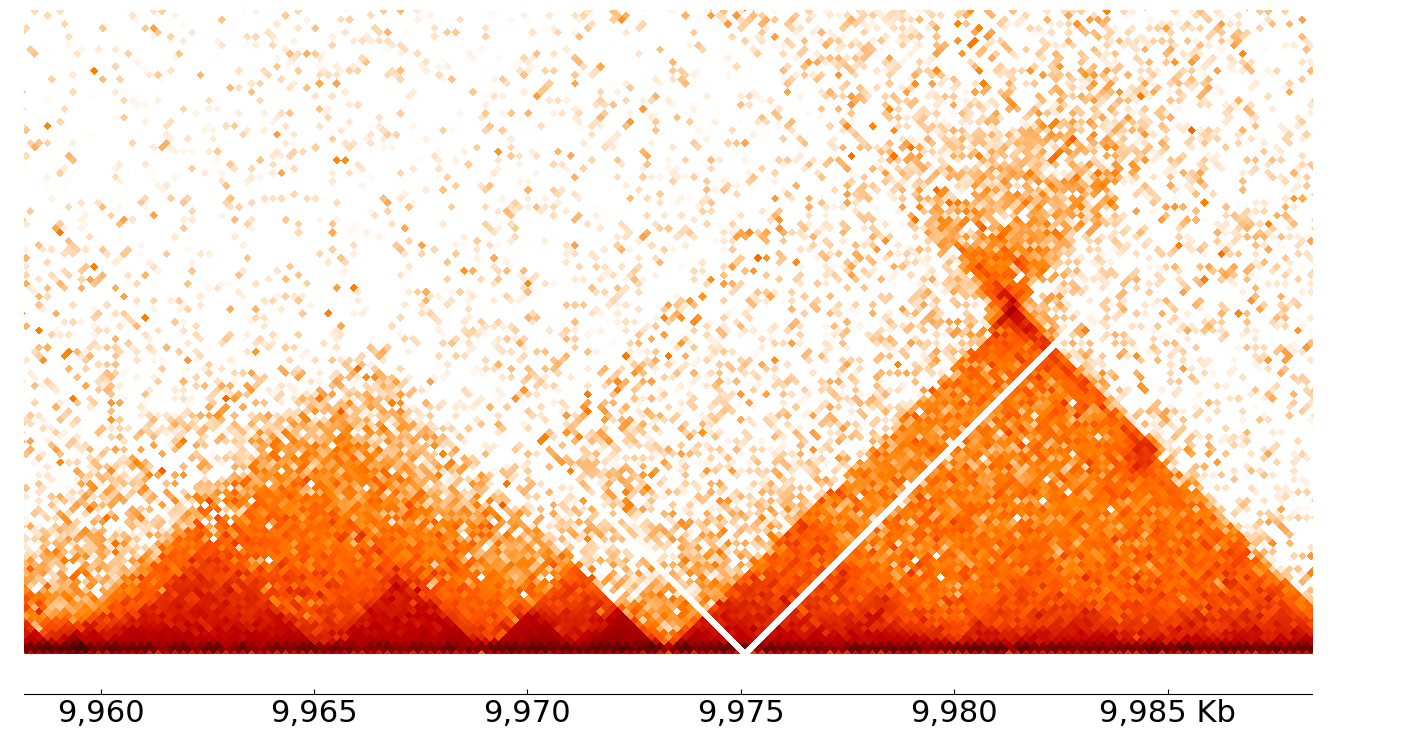

nc14_wt


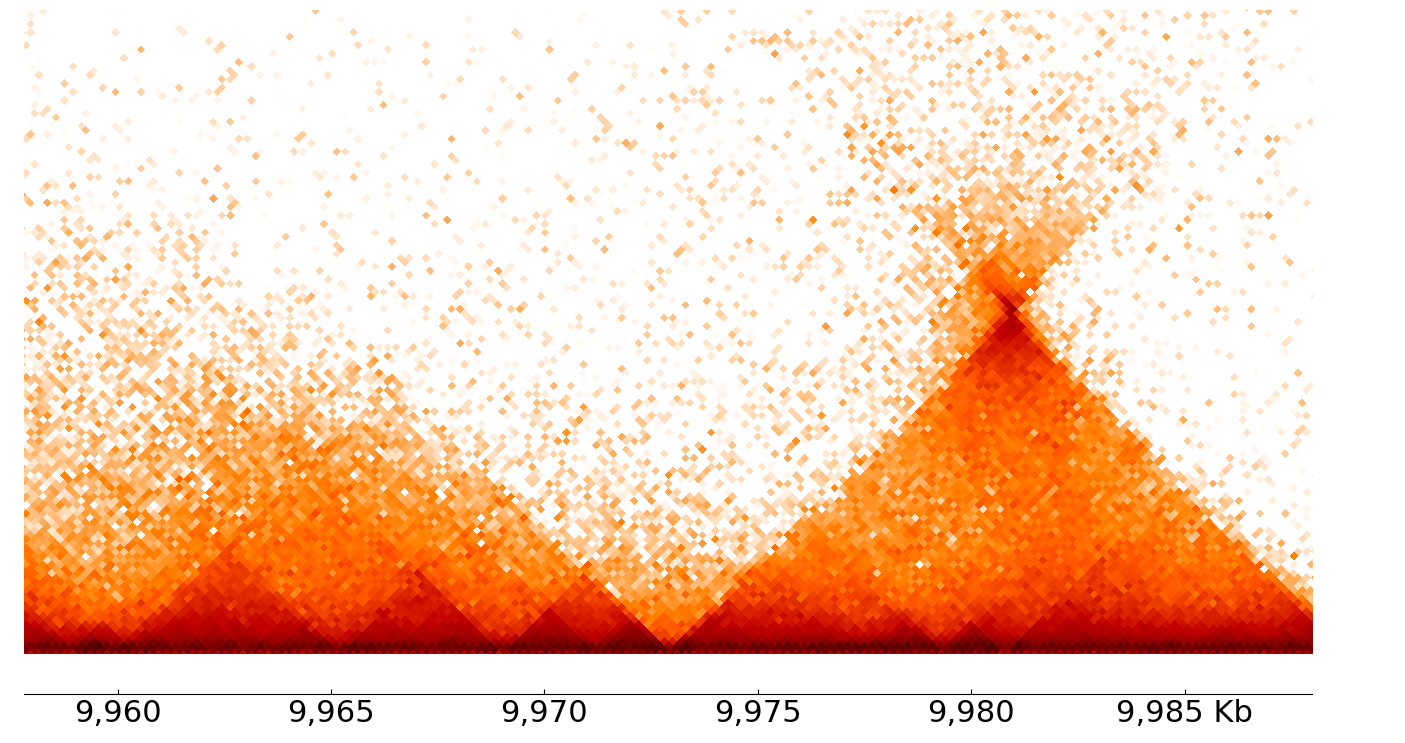

In [7]:
for i, mut in enumerate(mut2coords.keys()):
    print(mut)
    boundary = mut2coords[mut]
    
    plt.rcParams.update(plt.rcParamsDefault)
    plt.rcParams['pdf.fonttype'] = 42
    plt.rcParams['font.size'] = 25
    
    
    MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
    RESOLUTION=200
    NUM_MERGED=11
    
    chrom, start, end = mut2coords[mut]
    
    frame = [
        # Map
        coolbox.api.HiCMat(mut2mcool[mut], **HIC_KWARGS),
        coolbox.api.XAxis(fontsize=22, show_chrom=True),
        
    ]
    from functools import reduce
    
    
    frame = reduce(lambda x, y: x + y, frame)
    fig = frame.plot(f"{chrom}:{start-15_000}-{end + 15_000}")
    fig.set(facecolor="white")
    # fig.savefig(f"/scratch/gpfs/PRITYKIN/brendan/domino/figures/strong_pred_locus.pdf", format="pdf")
    display(fig)

In [8]:
def read_bedgraph_track(file, coords, window):
    df = pd.read_csv(file, sep='\t', header=None)
    df.columns = ['chrom', 'start', 'end', 'insulation']

    chrom, start, end = coords
    # print(chrom, start, end)

    idx = df.query('chrom == @chrom and start == @start and end == @end + 1').index.item()
    track = df.iloc[idx - window:idx + window+1].insulation
    
    return track.values

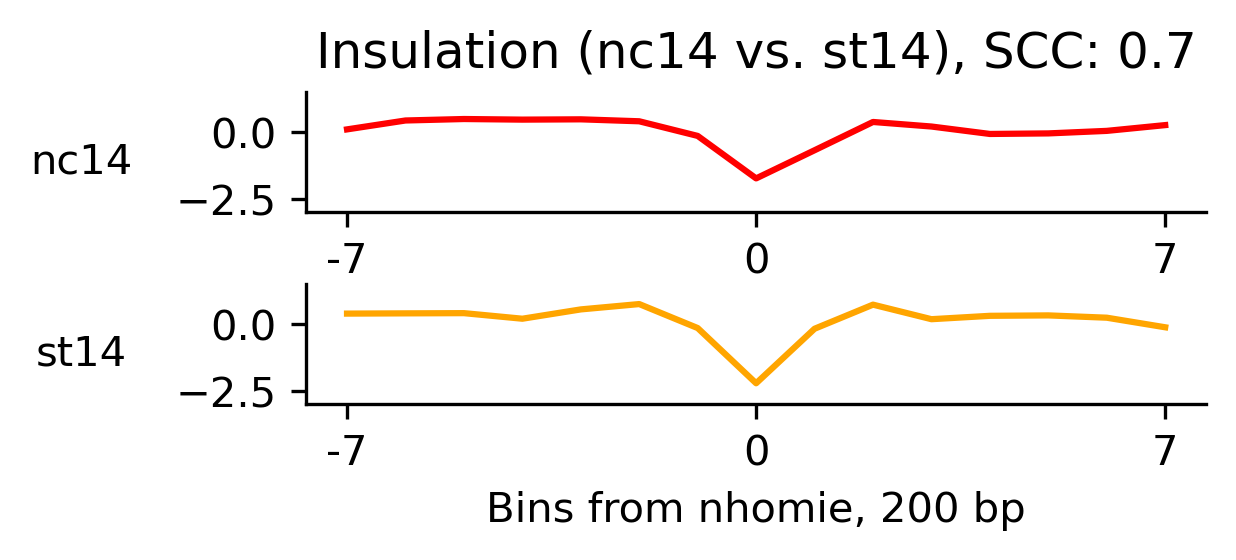

In [9]:
plt.rcdefaults()

fig, axs = init_subplots_exact(2,2,y_ratios=[0.1]*6, x_ratios=[0.75], yspace=1.6, dpi=300)

st14_track = read_bedgraph_track(f'st14_wt_mut_observed.bedGraph', coords=mut2coords['st14_wt'], window=1400//200)
nc14_track = read_bedgraph_track(f'nc14_wt_mut_observed.bedGraph', coords=mut2coords['nc14_wt'], window=1400//200)
    
i = 0

pcc = round(stats.pearsonr(st14_track, nc14_track)[0],3)
scc = round(stats.spearmanr(st14_track, nc14_track)[0],3)


axs[2*i].plot(np.arange(len(st14_track)), nc14_track, color='red', label='true')
axs[2*i].set_ylabel('nc14', rotation=0)
axs[2*i+1].plot(np.arange(len(st14_track)), st14_track, color='orange', label='pred')
axs[2*i+1].set_ylabel('st14', rotation=0)
axs[2*i].set_title(f'Insulation (nc14 vs. st14), SCC: {scc}')

for ax in axs:
    ax.yaxis.set_label_coords(-0.25, 0.25) 
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.set_ylim(-3, 1.5)
    
for ax in axs:
    ax.set_xticklabels([])
    ax.xaxis.set_ticks([])
    ax.set_xticks([0, 7, 14])
    ax.set_xticklabels([-7, 0, 7])

    ax.spines['bottom'].set_visible(True)
    ax.set_xlabel('Bins from nhomie, 200 bp')



# plt.savefig(f"/scratch/gpfs/PRITYKIN/brendan/domino/figures/boundary_replacement.pdf", format="pdf", bbox_inches='tight')
plt.show()

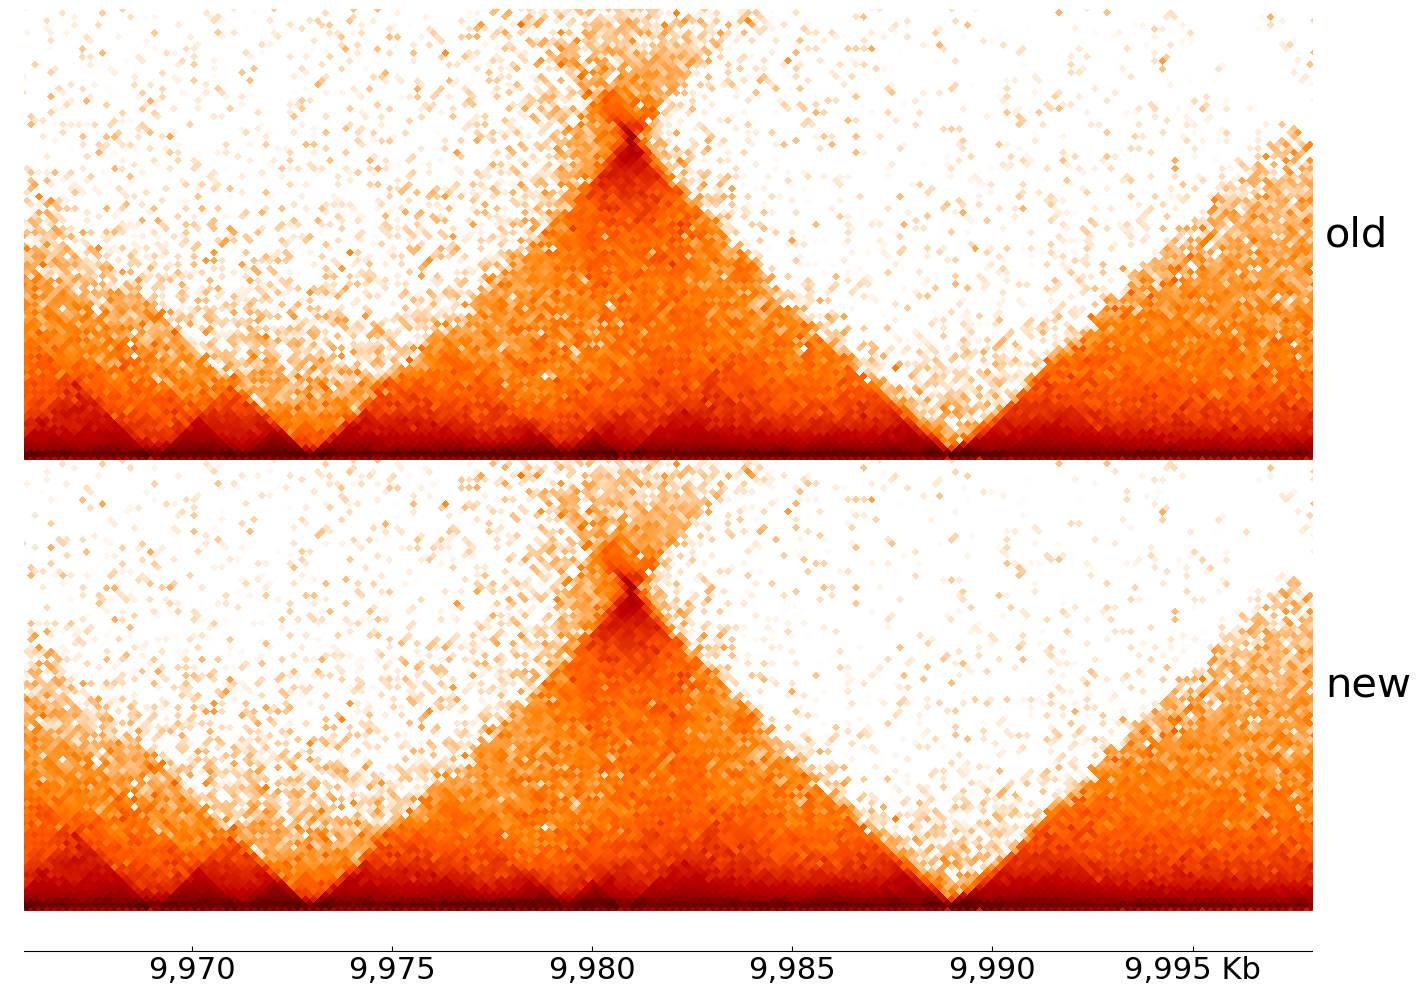

In [16]:
HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.7, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3.5, 
    grid=False,
    color_bar='no'
)

boundary = mut2coords['nc14_wt']

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 25
# plt.rcParams['font.family'] = ['Helvetica Neue', 'sans-serif']


chrom, start, end = mut2coords['nc14_wt']

frame = [
    # Map
    coolbox.api.HiCMat('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/nc14_embryo_merged_all_11.mcool', title='old', **HIC_KWARGS),
    coolbox.api.HiCMat('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/new_nc14_embryo_merged_all_11.mcool', title='new', **HIC_KWARGS),
    coolbox.api.XAxis(fontsize=22, show_chrom=True),
    
]
from functools import reduce


frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start-7_000}-{end + 25_000}")
fig.set(facecolor="white")
# fig.savefig(f"/scratch/gpfs/PRITYKIN/brendan/domino/figures/strong_pred_locus.pdf", format="pdf")
display(fig)